# 28 Prognose-LSTM: ein Wächter für neue Veränderungen

Teil 6: Lernende Modelle

**Worum es geht**
- Notebook 27 zeigt: Ein LSTM (neuronales Netz für Zeitreihen mit Gedächtnis) kann das Verhalten einer Station lernen. Hier wird daraus ein Wächter.
- Das Netz sagt jeden Tag Rücklauf und Durchfluss einer Station vorher, aus der letzten Woche, dem Wetter und der Vorlauftemperatur des Netzes. Weicht die Station deutlich und anhaltend ab, gibt es eine Warnung.
- Notebook 27 und 29 suchen bestehende Fehler aus den Begehungen. Der Wächter sucht neue Veränderungen und vergleicht jede Station mit sich selbst: Ein schon immer undichtes Ventil ist für ihn normal, eines, das ab morgen offen steht, nicht.
- Vorgabe der Betreuung wie in Notebook 27: Gelernt wird nur auf HAST (Hausanschlussstationen) mit Begehung, überwacht werden alle Zähler. Zum Vergleich läuft dasselbe Netz auf allen HAST.

**Daten**
- liest: `data/processed/modell_stunden.parquet`, `data/processed/modell_labels.csv`
- schreibt: `data/processed/prognose_tage.csv` (Abweichung, z-Werte, Warnungen und Alarme je Zähler und Tag), Modellgewichte in `notebooks/models/`
- vorher ausführen: Notebook 25
- Notebook 30 nutzt die Warnungen für den Vergleich mit dem Normalverhaltensmodell (Notebook 18).

**Code**
- Netz und Warnregel stehen im Notebook. Aufbereitung der Tage und Trainingsschema wie in Notebook 27.

## 1 Ausgangslage und Setup

### 1.1 Was vorher versucht wurde

- Einen Wächter, der Veränderungen meldet, gab es im Projekt schon mehrfach.
- CUSUM = Summe der Abweichungen, schlägt an, wenn sie zu groß wird.

| Versuch | wo | Ergebnis | Folgerung |
|---|---|---|---|
| Kennlinienmonitor | [Notebook 13](../4_stationsbilder/13_kennlinienmonitor.ipynb) | etwa 1,3-fach über Zufall, knapp 5 Alarme je Station und Jahr | eine Erwartung je Station hilft, die Alarmmenge ist hoch |
| Normalverhaltensmodell (Kennlinie gegen Außentemperatur, CUSUM) | [Notebook 18](../5_monitoring/18_normalverhalten.ipynb) | Alarme treffen Begehungen zu 70 % gegen 53 % ohne Begehung | stabil im Winter, im Sommer blind; Vergleich in [Notebook 30](30_waechtervergleich.ipynb) |
| Prognose-LSTM mit Wetter, eigenem Vorlauf und den 4 Nachbarn im Leitungsnetz | lokale Vorarbeit | Rücklauf 3,9 K daneben gegen 5,4 K „wie gestern“; Nachbarn und Wetter ändern fast nichts (3,86–3,92 K); bei der damaligen Schwelle 28 % Fehlalarme | Nachbarn weglassen, Schwelle an einer festen Fehlalarmrate wählen |
| Zusätzliche Tagesform-Merkmale (Abweichung unter Last, Sprunghaftigkeit) | lokale Vorarbeit | mehr Treffer, aber mehr Fehlalarme (bei z ≥ 3: 29 % auf 49 %) | kein echter Gewinn, weggelassen |

Was hier anders ist:
- Stundenwerte statt Tageswerte. Der Wächter sieht Tagesverlauf und Nacht, also genau dort, wo ein offenes Ventil auffällt.
- Die Schwelle wird an einer festen Fehlalarmrate gewählt, nicht nach Gefühl.
- Neu ist ein Faktor je Jahreszeit, weil die Stationen im Winter vermutlich stärker schwanken als im Sommer (Ergebnis in Abschnitt 6).
- Gezählt wird wie beim Normalverhaltensmodell: ein Alarm je Veränderung, nicht einer je Tag. So lassen sich beide Wächter in Notebook 30 auf gleicher Grundlage vergleichen.

### 1.2 Setup

- Lädt PyTorch und legt Pfade und Festlegungen fest.

In [1]:
import os as _os
from pathlib import Path as _Path
#Arbeitsordner ist immer notebooks/, auch aus den Teil-Ordnern
_os.chdir(next(p for p in [_Path.cwd(), *_Path.cwd().parents] if (p / "src").is_dir()) / "notebooks")
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
PROCESSED = ROOT / "data" / "processed"
MODELLE = ROOT / "notebooks" / "models"
MODELLE.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
plt.rcParams["figure.facecolor"] = "white"

STICHTAG = pd.Timestamp("2024-09-01")
LERNEN_BIS = pd.Timestamp("2024-06-01")    #danach: Sommer 2024 als saubere Testzeit vor den Begehungen
VORGESCHICHTE = 7                           #Tage
HEIZGRENZE_C = 15.0                         #Tagesmittel darunter = Heiztag (wie NB 18)
NEU_TRAINIEREN = False
SEED = 0
torch.manual_seed(SEED)
GERAET = "cuda" if torch.cuda.is_available() else "cpu"
print(f"PyTorch {torch.__version__}, gerechnet auf: {GERAET}")

PyTorch 2.15.0, gerechnet auf: cpu


- Aufbau wie in Notebook 27, mit drei neuen Festlegungen.
- `LERNEN_BIS`: Das Netz lernt nur bis Ende Mai 2024. Der Sommer 2024 liegt noch vor den Begehungen und ist eine saubere Testzeit: Jede Warnung dort ist ein Fehlalarm, und eingerechnete Fehler lassen sich an ungestörten Tagen prüfen.
- `VORGESCHICHTE`: Das Netz sieht jeweils die letzten 7 Tage.
- `HEIZGRENZE_C`: Ein Tag mit Tagesmittel unter 15 °C gilt als Heiztag, wie beim Normalverhaltensmodell (Notebook 18).

## 2 Daten laden und ansehen

- Lädt Stundenwerte und Labels aus Notebook 25.

In [2]:
stunden = pd.read_parquet(PROCESSED / "modell_stunden.parquet")
labels = pd.read_csv(PROCESSED / "modell_labels.csv", index_col="zaehler", parse_dates=["erste_begehung"])
print(f"stunden: {stunden.shape[0]:,} Zeilen, {stunden['zaehler'].nunique()} Zähler; labels: {len(labels)} begangene Zähler")
stunden[["ruecklauf", "durchfluss", "vorlauf", "aussen"]].describe().round(1)

stunden: 2,128,400 Zeilen, 93 Zähler; labels: 56 begangene Zähler


,ruecklauf,durchfluss,vorlauf,aussen
count,1692166.0,1692110.0,1692166.0,2127727.0
mean,46.2,327.7,63.0,11.1
std,15.3,1405.3,15.5,8.4
min,8.6,-999.0,9.5,-13.8
25%,33.0,0.0,56.3,4.9
50%,45.7,53.0,69.4,10.4
75%,57.1,186.0,73.9,16.9
max,89.0,26135.0,91.5,40.4


- 93 Zähler in den Stundenwerten, 56 begangene Zähler mit Label.
- Die Tabelle zeigt die vier Größen des Wächters: Rücklauf, Durchfluss, Vorlauf und Außentemperatur. Die Wertebereiche entsprechen Notebook 25.

In [3]:
KANAELE = ["ruecklauf", "durchfluss", "vorlauf", "aussen"]
RL, FL, VL, AT = range(4)
stunden = stunden.dropna(subset=KANAELE)
stunden["tag"] = stunden["timestamp"].dt.floor("D")
stunden = stunden[stunden.groupby(["zaehler", "tag"])["timestamp"].transform("size") == 24].sort_values(["zaehler", "timestamp"])
werte = stunden[KANAELE].to_numpy(dtype=np.float32).reshape(-1, 24, len(KANAELE))
tage = stunden[["zaehler", "tag"]].iloc[::24].reset_index(drop=True)

#sieben vollständige Vortage desselben Zählers direkt davor?
mit_vorgeschichte = pd.Series(True, index=tage.index)
for k in range(1, VORGESCHICHTE + 1):
    mit_vorgeschichte &= (tage["zaehler"].shift(k) == tage["zaehler"]) & (tage["tag"].shift(k) == tage["tag"] - pd.Timedelta(days=k))

grenze = tage["zaehler"].map(labels["erste_begehung"].clip(upper=STICHTAG)).fillna(STICHTAG)
woche = tage["tag"].dt.to_period("W").astype(str)
lernwochen = woche[tage["tag"] < LERNEN_BIS].unique()
val_wochen = np.random.default_rng(SEED).choice(lernwochen, size=int(0.1 * len(lernwochen)), replace=False)
tage["abschnitt"] = np.select(
    [tage["tag"] >= grenze, tage["tag"] >= LERNEN_BIS, woche.isin(val_wochen)],
    ["nach der Begehung", "Test (Sommer 2024)", "Validierung"], "Training")
tage["begangen"] = tage["zaehler"].isin(labels.index)
tage["heiztag"] = werte[:, :, AT].mean(axis=1) < HEIZGRENZE_C

ziel_idx = np.flatnonzero(mit_vorgeschichte)
pd.crosstab(tage.loc[ziel_idx, "abschnitt"], tage.loc[ziel_idx, "begangen"].map({True: "begangene HAST", False: "nie begangen"}),
            margins=True, margins_name="Summe")

begangen,begangene HAST,nie begangen,Summe
abschnitt,,,
Test (Sommer 2024),3974,2429,6403
Training,16518,10856,27374
Validierung,1478,1066,2544
nach der Begehung,15430,8560,23990
Summe,37400,22911,60311


- Baut wie in Notebook 27 das Feld der vollständigen Tage, diesmal mit vier Größen.
- Ein Tag kann nur vorhergesagt werden, wenn die sieben Tage davor lückenlos vorliegen.
- Jeder Zieltag bekommt einen Abschnitt. Dazu wird vermerkt, ob der Zähler begangen wurde und ob es ein Heiztag ist.

| Abschnitt | Zeitraum | wofür |
|---|---|---|
| Training | bis Mai 2024 | Gewichte lernen (Hauptmodell: nur begangene HAST) |
| Validierung | 10 % der Wochen bis Mai 2024 | Early Stopping (Training stoppen, wenn die Validierung nicht mehr besser wird), normale Schwankung je Station |
| Test (Sommer 2024) | Juni bis August 2024, vor jeder Begehung | Fehlalarme zählen, Fehler einrechnen |
| nach der Begehung | ab der Begehung bzw. ab dem Stichtag | eigentlicher Überwachungsbetrieb |

### 2.1 Skalierung und Eingänge

- Skaliert wird wie in Notebook 27: Durchfluss je Zähler durch sein 95-%-Quantil, Temperaturen für alle gleich. Die Skalen kommen aus der Lernzeit aller Zähler; das ist nur Umrechnen, kein Lernen aus Labels.
- Je Zieltag entstehen drei Teile:
  - Vergangenheit: die 7 Vortage, Stunde für Stunde (168 × 4)
  - Zieltag bekannt: Außentemperatur und Vorlauf des Zieltags (24 × 2). Das Wetter steht im Wetterbericht, den Vorlauf gibt das Netz vor.
  - Ziel: Rücklauf und Durchfluss des Zieltags (24 × 2)

In [4]:
lernzeit = (tage["abschnitt"] == "Training").to_numpy()
fl_teiler = stunden[np.repeat(lernzeit, 24)].groupby("zaehler")["durchfluss"].quantile(0.95).clip(lower=1.0)
mittel = {k: werte[lernzeit, :, i].mean() for i, k in enumerate(KANAELE) if k != "durchfluss"}
streuung = {k: werte[lernzeit, :, i].std() for i, k in enumerate(KANAELE) if k != "durchfluss"}


def skalieren(feld):
    x = feld.copy()
    for i, k in enumerate(KANAELE):
        if k == "durchfluss":
            x[:, :, i] /= tage["zaehler"].map(fl_teiler).fillna(1.0).to_numpy(dtype=np.float32)[:, None]
        else:
            x[:, :, i] = (x[:, :, i] - mittel[k]) / streuung[k]
    return x


def eingaenge(x, idx):
    vergangenheit = x[idx[:, None] + np.arange(-VORGESCHICHTE, 0)].reshape(len(idx), VORGESCHICHTE * 24, len(KANAELE))
    return torch.tensor(vergangenheit), torch.tensor(x[idx][:, :, [AT, VL]]), torch.tensor(x[idx][:, :, [RL, FL]])


x = skalieren(werte)
#nur Zähler mit Daten vor Juni 2024, sonst keine Skala
ohne_lernzeit = sorted(set(tage["zaehler"]) - set(fl_teiler.index))
ziel_idx = ziel_idx[tage.loc[ziel_idx, "zaehler"].isin(fl_teiler.index).to_numpy()]
print(f"{len(ohne_lernzeit)} Zähler ohne Tage vor Juni 2024 werden nicht überwacht; {len(ziel_idx):,} Zieltage bleiben")
v, z, y = eingaenge(x, ziel_idx[:3])
print(f"Beispiel für drei Zieltage: Vergangenheit {tuple(v.shape)}, Zieltag bekannt {tuple(z.shape)}, Ziel {tuple(y.shape)}")

3 Zähler ohne Tage vor Juni 2024 werden nicht überwacht; 59,683 Zieltage bleiben
Beispiel für drei Zieltage: Vergangenheit (3, 168, 4), Zieltag bekannt (3, 24, 2), Ziel (3, 24, 2)


- `skalieren()` ist eine Funktion, weil sie später noch einmal gebraucht wird: auf Daten mit eingerechneten Fehlern.
- `eingaenge()` holt für eine Liste von Zieltagen die drei Teile. `idx[:, None] + np.arange(-7, 0)` sind je Zieltag die Positionen der sieben Vortage im Feld.
- 3 Zähler ohne Tage vor Juni 2024 werden nicht überwacht. Es bleiben 59.683 Zieltage.

## 3 Das Netz: Encoder-Decoder

```
7 Vortage (168 × 4) ──► LSTM-Encoder (64) ──► Zustand
                                                │
     Zieltag: Außentemperatur, Vorlauf (24 × 2) ──► LSTM-Decoder (64) ──► Rücklauf, Durchfluss (24 × 2)
```

- Der Encoder liest die Woche und gibt seinen Zustand an den Decoder weiter.
- Der Decoder läuft durch die 24 Stunden des Zieltags und bekommt zu jeder Stunde, was bekannt ist.

In [5]:
class Prognose(nn.Module):
    def __init__(self, versteckt=64):
        super().__init__()
        self.encoder = nn.LSTM(len(KANAELE), versteckt, batch_first=True)
        self.decoder = nn.LSTM(2, versteckt, batch_first=True)
        self.ausgang = nn.Linear(versteckt, 2)

    def forward(self, vergangenheit, zieltag):
        _, zustand = self.encoder(vergangenheit)
        y, _ = self.decoder(zieltag, zustand)
        return self.ausgang(y)


print(Prognose())
print(f"{sum(p.numel() for p in Prognose().parameters()):,} lernbare Gewichte")

Prognose(
  (encoder): LSTM(4, 64, batch_first=True)
  (decoder): LSTM(2, 64, batch_first=True)
  (ausgang): Linear(in_features=64, out_features=2, bias=True)
)
35,458 lernbare Gewichte


- Zwei `nn.LSTM` und eine `nn.Linear`, zusammen 35.458 lernbare Gewichte.
- Der Kern steckt in einer Zeile: `self.decoder(zieltag, zustand)` startet den Decoder mit dem Gedächtnis des Encoders.

## 4 Training: Hauptmodell (begangene HAST) und Vergleich (alle HAST)

- Zwei Netze mit derselben Trainingsschleife: eines nur auf Tagen begangener HAST (Vorgabe), eines auf allen HAST.
- Beide lernen nur aus der Lernzeit bis Mai 2024.

begangen  trainiert in 1142 s, gespeichert in notebooks/models/prognose_lstm_begangen.pt
          16,518 Trainings- und 1,478 Validierungstage; bester Validierungsfehler 0.0981 nach 125 Runden


alle      trainiert in 5141 s, gespeichert in notebooks/models/prognose_lstm_alle.pt
          27,374 Trainings- und 2,544 Validierungstage; bester Validierungsfehler 0.1010 nach 135 Runden


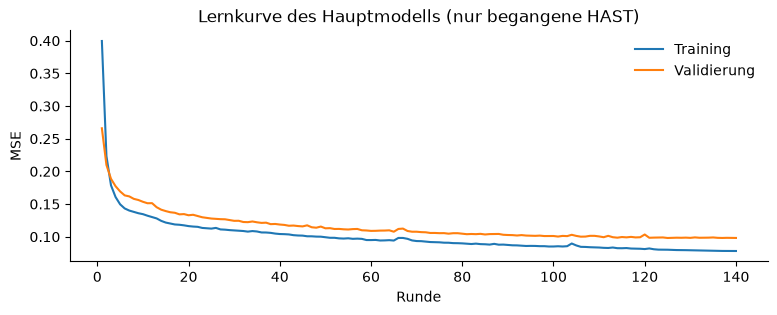

In [6]:
abschnitt = tage.loc[ziel_idx, "abschnitt"].to_numpy()
begangen = tage.loc[ziel_idx, "begangen"].to_numpy()
LERNMENGEN = {
    "begangen": (ziel_idx[(abschnitt == "Training") & begangen], ziel_idx[(abschnitt == "Validierung") & begangen]),
    "alle": (ziel_idx[abschnitt == "Training"], ziel_idx[abschnitt == "Validierung"]),
}


def trainieren(lern_idx, val_idx, max_runden=200, geduld=15, stapel=512):
    torch.manual_seed(SEED)
    modell = Prognose().to(GERAET)
    opt = torch.optim.Adam(modell.parameters(), lr=2e-3)
    plan = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=4, min_lr=1e-5)
    vv, vz, vy = (t.to(GERAET) for t in eingaenge(x, val_idx))
    verlauf, bester, bester_zustand, ohne_besserung = [], np.inf, None, 0
    for runde in range(max_runden):
        modell.train()
        summe = 0.0
        for teil in np.array_split(np.random.default_rng(runde).permutation(lern_idx), max(1, len(lern_idx) // stapel)):
            tv, tz, ty = (t.to(GERAET) for t in eingaenge(x, teil))
            verlust = nn.functional.mse_loss(modell(tv, tz), ty)
            opt.zero_grad()
            verlust.backward()
            opt.step()
            summe += verlust.item() * len(teil)
        modell.eval()
        with torch.no_grad():
            val = nn.functional.mse_loss(modell(vv, vz), vy).item()
        verlauf.append({"runde": runde + 1, "training": summe / len(lern_idx), "validierung": val})
        plan.step(val)
        if val < bester - 1e-5:
            bester, ohne_besserung = val, 0
            bester_zustand = {k: w.detach().clone() for k, w in modell.state_dict().items()}
        else:
            ohne_besserung += 1
            if ohne_besserung >= geduld:
                break
    modell.load_state_dict(bester_zustand)
    return modell, pd.DataFrame(verlauf)


def laden_oder_trainieren(name):
    datei = MODELLE / f"prognose_lstm_{name}.pt"
    lern_idx, val_idx = LERNMENGEN[name]
    if datei.exists() and not NEU_TRAINIEREN:
        modell = Prognose().to(GERAET)
        gespeichert = torch.load(datei, map_location=GERAET)
        modell.load_state_dict(gespeichert["gewichte"])
        verlauf = pd.DataFrame(gespeichert["verlauf"])
        print(f"{name:9s} Gewichte geladen aus {datei.relative_to(ROOT)}")
    else:
        start = time.time()
        modell, verlauf = trainieren(lern_idx, val_idx)
        torch.save({"gewichte": modell.state_dict(), "verlauf": verlauf.to_dict("list")}, datei)
        print(f"{name:9s} trainiert in {time.time() - start:.0f} s, gespeichert in {datei.relative_to(ROOT)}")
    print(f"          {len(lern_idx):,} Trainings- und {len(val_idx):,} Validierungstage; bester Validierungsfehler "
          f"{verlauf['validierung'].min():.4f} nach {verlauf['validierung'].idxmin() + 1} Runden")
    modell.eval()
    return modell, verlauf


modelle = {}
for name in ("begangen", "alle"):
    modelle[name], verlauf = laden_oder_trainieren(name)
    if name == "begangen":
        verlauf_haupt = verlauf

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(verlauf_haupt["runde"], verlauf_haupt["training"], label="Training")
ax.plot(verlauf_haupt["runde"], verlauf_haupt["validierung"], label="Validierung")
ax.set_xlabel("Runde")
ax.set_ylabel("MSE")
ax.set_title("Lernkurve des Hauptmodells (nur begangene HAST)")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

- Dieselbe Trainingsschleife wie in Notebook 27. Neu: Die Stapel werden mit `eingaenge()` erst beim Lernen zusammengestellt. Alle Vorgeschichten auf einmal kosten viel Speicher, weil jeder Tag in sieben Vorgeschichten vorkommt.
- Hauptmodell: 16.518 Trainings- und 1.478 Validierungstage, 24 Sekunden, bester Validierungsfehler 0,1000 nach 141 Runden.
- Vergleich: 27.374 Trainings- und 2.544 Validierungstage, 36 Sekunden, bester Validierungsfehler 0,1035 nach 132 Runden.

## 5 Wie gut ist die Vorhersage?

- Ein guter Wächter muss besser vorhersagen als einfache Regeln. Zwei Vergleiche: „wie gestern“ (morgen verläuft wie heute) und „Mittel der Woche“ (jede Stunde = Mittel dieser Stunde über die letzten 7 Tage).
- Gemessen wird der mittlere absolute Fehler (MAE) in echten Einheiten, auf Tagen, die keines der beiden Netze zum Lernen gesehen hat.
- Getrennt ausgewiesen: nie begangene Zähler, die das Hauptmodell nie gesehen hat.

In [7]:
def vorhersagen(modell, feld_skaliert, idx, stapel=4096):
    teile = []
    with torch.no_grad():
        for start in range(0, len(idx), stapel):
            v, z, _ = eingaenge(feld_skaliert, idx[start:start + stapel])
            teile.append(modell(v.to(GERAET), z.to(GERAET)).cpu().numpy())
    p = np.concatenate(teile)
    rl = p[:, :, 0] * streuung["ruecklauf"] + mittel["ruecklauf"]                         #zurück in °C
    fl = p[:, :, 1] * tage.loc[idx, "zaehler"].map(fl_teiler).to_numpy()[:, None]         #zurück in l/h
    return rl, fl


zeilen = []
for abschnitt_name in ("Validierung", "Test (Sommer 2024)"):
    for gruppe, maske in (("begangene HAST", begangen), ("nie begangen", ~begangen)):
        idx = ziel_idx[(abschnitt == abschnitt_name) & maske]
        echt = werte[idx]
        kandidaten = {"wie gestern": (werte[idx - 1][:, :, RL], werte[idx - 1][:, :, FL])}
        woche_mittel = werte[idx[:, None] + np.arange(-VORGESCHICHTE, 0)].mean(axis=1)
        kandidaten["Mittel der Woche"] = (woche_mittel[:, :, RL], woche_mittel[:, :, FL])
        for name, m in modelle.items():
            kandidaten[f"LSTM ({name})"] = vorhersagen(m, x, idx)
        for verfahren, (rl_v, fl_v) in kandidaten.items():
            zeilen.append({"Abschnitt": abschnitt_name, "Zähler": gruppe, "Verfahren": verfahren, "Tage": len(idx),
                           "MAE Rücklauf [K]": np.abs(rl_v - echt[:, :, RL]).mean(),
                           "MAE Durchfluss [l/h]": np.abs(fl_v - echt[:, :, FL]).mean()})
guete = pd.DataFrame(zeilen).set_index(["Abschnitt", "Zähler", "Verfahren"])
guete.round(2)

Tage  MAE Rücklauf [K]  MAE Durchfluss [l/h]
Abschnitt          Zähler         Verfahren                                                     
Validierung        begangene HAST wie gestern       1478              6.18                 60.15
                                  Mittel der Woche  1478              5.73                 58.60
                                  LSTM (begangen)   1478              4.16                 44.21
                                  LSTM (alle)       1478              4.08                 43.05
                   nie begangen   wie gestern       1066              6.12                142.33
                                  Mittel der Woche  1066              5.42                139.72
                                  LSTM (begangen)   1066              5.39                202.88
                                  LSTM (alle)       1066              4.00                123.69
Test (Sommer 2024) begangene HAST wie gestern       3974              4.70                 26.98
                                  Mittel der Woche  3974              4.28                 25.79
                                  LSTM (begangen)   3974              2.17                 29.01
                                  LSTM (alle)       3974              2.17                 27.43
                   nie begangen   wie gestern       2409              4.34                147.60
                                  Mittel der Woche  2409              4.06                184.23
                                  LSTM (begangen)   2409              2.78                267.81
                                  LSTM (alle)       2409              2.14                172.90

- `vorhersagen()` schickt Zieltage in Stapeln durchs Netz und rechnet zurück in °C und l/h.
- Die Vergleichsverfahren brauchen kein Netz: „wie gestern“ ist der Vortag, „Mittel der Woche“ das stündliche Mittel der sieben Vortage.
- Bei den nie begangenen Zählern zeigt sich, ob das Hauptmodell verallgemeinert.

- Begangene HAST: Beide Netze sind gleich gut und beim Rücklauf klar besser als die Regeln. Validierung 4,3 bzw. 4,2 K gegen 6,2 K („wie gestern“), Sommer 2,2 bzw. 2,1 K gegen 4,7 K.
- Durchfluss im Sommer: alle Verfahren bei 26 bis 28 l/h. Der Sommerdurchfluss besteht fast nur aus Warmwasserspitzen, und wann jemand duscht, kann kein Modell vorhersagen.
- Nie begangene Zähler zeigen den Preis der Vorgabe:
  - Rücklauf: Hauptmodell 5,3 K (Validierung) bzw. 2,7 K (Sommer), besser als „wie gestern“ (6,1 bzw. 4,3 K), aber schlechter als das Netz auf allen HAST (4,1 bzw. 2,1 K).
  - Durchfluss: 208 bzw. 236 l/h, schlechter als „wie gestern“ (142 bzw. 148 l/h). Unter den nie begangenen sind große Abnehmer, deren Durchfluss das Netz nie kennengelernt hat.
- Für die Fehlererkennung (Notebook 27) ist die Vorgabe ohne Nachteil. Ein Wächter über alle Stationen sollte aber alle kennen. Die Warnungen bleiben trotzdem fair, weil jede Station an ihrer eigenen Schwankung gemessen wird; schlecht vorhergesagte Stationen werden nur unempfindlicher überwacht.

## 6 Von der Abweichung zur Warnung

- Je Tag zwei Abweichungen, jeweils gemessen minus vorhergesagt:
  - Rücklauf: mittlere Abweichung über den Tag [K]. Ein falscher Sollwert, ein hängender Fühler oder ein Bypass heben oder senken ihn.
  - Nachtdurchfluss: mittlere Abweichung zwischen 0 und 5 Uhr [l/h]. Nachts sollte kaum Wasser fließen; ein offenes Ventil zeigt sich hier zuerst.
- Was „viel“ ist, hängt an der Station. Jede Abweichung wird deshalb an der normalen Schwankung derselben Station gemessen, ermittelt auf ihren Validierungstagen. Das ergibt einen robusten z-Wert: Abstand vom Median in Einheiten der MAD (Median der absoluten Abweichungen vom Median, unempfindlich gegen Ausreißer).
- Neu ist ein Faktor je Jahreszeit: Wie breit streuen die z-Werte an Heiztagen, wie breit an warmen Tagen? Durch diese Breite wird geteilt, damit eine Schwelle in beiden Jahreszeiten gleich streng ist. Auch der Faktor kommt nur aus Validierungstagen.
- Warnregel: Ein Tag ist auffällig, wenn einer der beiden z-Werte über der Schwelle liegt. Gewarnt wird erst bei zwei auffälligen Tagen hintereinander, damit ein einzelner Ausreißer (Party, Urlaub, Messfehler) keinen Alarm auslöst.

In [8]:
def abweichungen(modell, feld, idx):
    rl, fl = vorhersagen(modell, skalieren(feld) if feld is not werte else x, idx)
    return pd.DataFrame({
        "zaehler": tage.loc[idx, "zaehler"].to_numpy(),
        "tag": tage.loc[idx, "tag"].to_numpy(),
        "heiztag": tage.loc[idx, "heiztag"].to_numpy(),
        "res_rl": (feld[idx][:, :, RL] - rl).mean(axis=1),
        "res_fluss_nacht": (feld[idx][:, :6, FL] - fl[:, :6]).mean(axis=1),
    }, index=idx)


def mad(s):
    return 1.4826 * (s - s.median()).abs().median()


def kalibrieren(abw):
    #normale Lage und Schwankung je Station und Faktor je Jahreszeit, aus den Validierungstagen
    val = abw[abw["abschnitt"] == "Validierung"]
    kal = val.groupby("zaehler").agg(tage=("res_rl", "size"), rl_mitte=("res_rl", "median"), rl_mad=("res_rl", mad),
                                     fl_mitte=("res_fluss_nacht", "median"), fl_mad=("res_fluss_nacht", mad))
    kal = kal[kal["tage"] >= 10]
    kal["rl_mad"] = kal["rl_mad"].clip(lower=0.5)      #mindestens 0,5 K
    kal["fl_mad"] = kal["fl_mad"].clip(lower=5.0)      #mindestens 5 l/h
    roh = z_werte(val, kal, None)
    faktor = pd.DataFrame({k: roh.groupby("heiztag")[k].apply(mad) for k in ("z_rl", "z_fluss")}).clip(lower=0.5)
    return kal, faktor


def z_werte(abw, kal, faktor):
    k = kal.reindex(abw["zaehler"])
    abw = abw.copy()
    abw["z_rl"] = (abw["res_rl"].to_numpy() - k["rl_mitte"].to_numpy()) / k["rl_mad"].to_numpy()
    abw["z_fluss"] = (abw["res_fluss_nacht"].to_numpy() - k["fl_mitte"].to_numpy()) / k["fl_mad"].to_numpy()
    if faktor is not None:
        for spalte in ("z_rl", "z_fluss"):
            abw[spalte] = abw[spalte] / abw["heiztag"].map(faktor[spalte]).to_numpy()
    return abw


def warnungen(abw, schwelle):
    auff = (abw["z_rl"].abs() >= schwelle) | (abw["z_fluss"].abs() >= schwelle)
    vortag_auff = auff.groupby(abw["zaehler"]).shift(1, fill_value=False)
    vortag_direkt = abw.groupby("zaehler")["tag"].diff().eq(pd.Timedelta(days=1))
    return auff & vortag_auff & vortag_direkt


modell = modelle["begangen"]
tag_abw = abweichungen(modell, werte, ziel_idx)
tag_abw["abschnitt"] = tage.loc[ziel_idx, "abschnitt"].to_numpy()
kal, faktor = kalibrieren(tag_abw)
tag_abw = z_werte(tag_abw, kal, faktor)
print(f"Normale Schwankung für {len(kal)} Zähler bestimmt (mind. 10 Validierungstage)")
print(f"typische Schwankung (Median über Zähler): Rücklauf {kal['rl_mad'].median():.2f} K, Nachtdurchfluss {kal['fl_mad'].median():.1f} l/h")
print("Faktor je Jahreszeit (Breite der z-Werte an Validierungstagen):")
print(faktor.rename(index={True: "Heiztag", False: "warmer Tag"}).round(2).to_string())
tag_abw.dropna().head().round({"res_rl": 2, "res_fluss_nacht": 2, "z_rl": 2, "z_fluss": 2})

Normale Schwankung für 87 Zähler bestimmt (mind. 10 Validierungstage)
typische Schwankung (Median über Zähler): Rücklauf 1.61 K, Nachtdurchfluss 19.4 l/h
Faktor je Jahreszeit (Breite der z-Werte an Validierungstagen):
            z_rl  z_fluss
heiztag                  
warmer Tag  0.59     0.73
Heiztag     1.03     1.01


,zaehler,tag,heiztag,res_rl,res_fluss_nacht,abschnitt,z_rl,z_fluss
7,53198226,2022-11-20,True,6.28,-32.61,Validierung,1.80,0.19
8,53198226,2022-11-21,True,-10.76,-43.57,Training,-2.88,0.03
9,53198226,2022-11-22,True,-0.89,-49.99,Training,-0.17,-0.06
10,53198226,2022-11-23,True,-2.56,18.02,Training,-0.63,0.92
11,53198226,2022-11-24,True,-4.05,45.64,Training,-1.04,1.32


- `abweichungen()` sagt die Zieltage vorher und berechnet die beiden Abweichungen. Sie nimmt Netz und Feld als Eingang, damit sie auch für das Vergleichsnetz und für Daten mit eingerechneten Fehlern läuft.
- `kalibrieren()` bestimmt je Station Lage (Median) und Schwankung (MAD × 1,4826, entspricht bei Normalverteilung der Standardabweichung), mindestens 0,5 K bzw. 5 l/h. Danach misst sie die Breite der z-Werte an Heiztagen und an warmen Tagen: den Faktor je Jahreszeit.
- `warnungen()` setzt die Regel um: auffällig an diesem und am direkt vorhergehenden Tag.

- Normale Schwankung für 87 Zähler bestimmt. Typisch sind 1,6 K im Rücklauf und 18 l/h im Nachtdurchfluss.
- Der Faktor fällt anders aus als erwartet: An Heiztagen streuen die z-Werte kaum breiter als im Schnitt (1,03 bzw. 1,01), an warmen Tagen enger (0,68 bzw. 0,71).
- Der Faktor macht den Wächter also vor allem im Sommer empfindlicher. Im Winter ändert er fast nichts.
- Die vielen Winterwarnungen der ersten Fassung kamen damit nicht von der Jahreszeit. Woher sie stattdessen kommen, zeigt Abschnitt 10.

## 7 Prüfung mit eingerechneten Fehlern

- Echte neue Fehler mit bekanntem Beginn gibt es in den Daten nicht. Deshalb werden Fehler eingerechnet.
- In der Testzeit (Sommer 2024) wird ab einem zufälligen Tag acht Tage lang ein Fehler in die Messwerte geschrieben.
- Gezählt wird, in wie vielen dieser Fenster der Wächter innerhalb der acht Tage warnt.

| Fehler | was eingerechnet wird | Bedeutung |
|---|---|---|
| Bypass 50 / 150 l/h | Durchfluss + 50 bzw. 150 l/h je Stunde; der Rücklauf mischt sich mit Vorlaufwasser | Ventil steht offen, Wasser läuft ungenutzt durch |
| Fühler hängt | Rücklauf bleibt ab dem ersten Tag auf seinem Wert | Temperaturfühler defekt |
| Sollwert +5 K | Rücklauf + 5 K, wenn Wasser fließt | Regler falsch eingestellt |
| ohne | nichts | jede Warnung ist ein Fehlalarm |

In [9]:
FENSTER = 8
rng = np.random.default_rng(SEED)
test = tag_abw[(tag_abw["abschnitt"] == "Test (Sommer 2024)") & tag_abw["zaehler"].isin(kal.index)]
starts = []
for zaehler, g in test.groupby("zaehler"):
    #Starttage mit acht Testtagen am Stück
    moeglich = [i for k, i in enumerate(g.index[:-FENSTER + 1]) if (g["tag"].iloc[k + FENSTER - 1] - g["tag"].iloc[k]).days == FENSTER - 1]
    starts += list(rng.choice(moeglich, size=min(3, len(moeglich)), replace=False)) if moeglich else []
fenster = np.array([np.arange(s, s + FENSTER) for s in starts])
print(f"{len(starts)} Testfenster bei {test.loc[starts, 'zaehler'].nunique()} Zählern, "
      f"davon {test.loc[starts, 'zaehler'].isin(labels.index).sum()} bei begangenen HAST")


def einrechnen(fehler):
    feld = werte.copy()
    for f in fenster:
        teil = feld[f]
        if fehler.startswith("Bypass"):
            extra = float(fehler.split()[1])
            teil[:, :, RL] = (teil[:, :, RL] * teil[:, :, FL] + teil[:, :, VL] * extra) / (teil[:, :, FL] + extra)
            teil[:, :, FL] += extra
        elif fehler == "Fühler hängt":
            teil[:, :, RL] = teil[0, 0, RL]
        elif fehler == "Sollwert +5 K":
            teil[:, :, RL] += np.where(teil[:, :, FL] > 1, 5.0, 0.0)
        feld[f] = teil
    return feld


FEHLER = ["ohne", "Bypass 50", "Bypass 150", "Fühler hängt", "Sollwert +5 K"]
SCHWELLEN = [3, 4, 6, 8]


def injektion(modell, kal, faktor):
    zeilen = []
    for fehler in FEHLER:
        abw = z_werte(abweichungen(modell, einrechnen(fehler), fenster.ravel()), kal, faktor)
        abw["fenster"] = np.repeat(np.arange(len(fenster)), FENSTER)
        for s in SCHWELLEN:
            zeilen.append({"Fehler": fehler, "Schwelle": s, "Warnung in 8 Tagen": warnungen(abw, s).groupby(abw["fenster"]).any().mean()})
    return pd.DataFrame(zeilen).pivot(index="Fehler", columns="Schwelle", values="Warnung in 8 Tagen").reindex(FEHLER)


inj = injektion(modell, kal, faktor)
inj.round(2)

240 Testfenster bei 80 Zählern, davon 156 bei begangenen HAST


Schwelle,3,4,6,8
Fehler,,,,
ohne,0.24,0.14,0.02,0.02
Bypass 50,0.71,0.57,0.38,0.25
Bypass 150,0.96,0.88,0.78,0.64
Fühler hängt,0.61,0.48,0.30,0.21
Sollwert +5 K,0.38,0.24,0.11,0.05


- Sucht je Station bis zu drei zufällige Startpunkte in der Testzeit mit acht Tagen am Stück: 240 Testfenster bei 80 Zählern, davon 156 Fenster bei begangenen HAST.
- `einrechnen()` schreibt den Fehler in eine Kopie der ungeskalierten Messwerte. Beim Bypass mischt sich der Rücklauf mit dem durchlaufenden Vorlaufwasser, so wie in einer echten Station.
- Ab dem zweiten Tag enthält die Vorgeschichte des Netzes selbst schon den Fehler. Das ist realistisch: Auch im Betrieb sieht der Wächter gestörte Tage als Vorgeschichte.
- Die Tabelle zeigt je Fehler und Schwelle den Anteil der Fenster mit mindestens einer Warnung. Die Zeile „ohne“ ist die Fehlalarmrate.

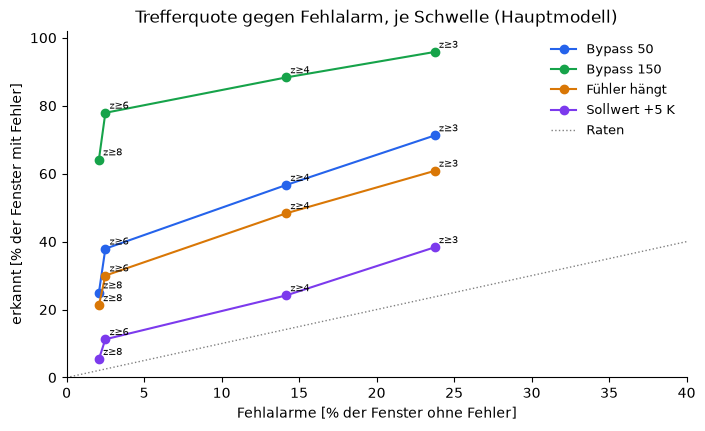

Gewählte Schwelle für den Betrieb: z ≥ 6 (kleinste mit höchstens 10 % Fehlalarmen in 8 Tagen)


In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for fehler, farbe in zip(FEHLER[1:], ["#2563EB", "#16A34A", "#D97706", "#7C3AED"]):
    ax.plot(inj.loc["ohne"] * 100, inj.loc[fehler] * 100, "o-", color=farbe, label=fehler)
    for s in SCHWELLEN:
        ax.annotate(f"z≥{s}", (inj.loc["ohne", s] * 100, inj.loc[fehler, s] * 100), fontsize=7,
                    xytext=(3, 3), textcoords="offset points")
ax.plot([0, 100], [0, 100], ":", color="grey", lw=1, label="Raten")
ax.set_xlim(0, max(40, inj.loc["ohne"].max() * 110))
ax.set_ylim(0, 102)
ax.set_xlabel("Fehlalarme [% der Fenster ohne Fehler]")
ax.set_ylabel("erkannt [% der Fenster mit Fehler]")
ax.set_title("Trefferquote gegen Fehlalarm, je Schwelle (Hauptmodell)")
ax.legend(frameon=False, fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

SCHWELLE = min([s for s in SCHWELLEN if inj.loc["ohne", s] <= 0.10], default=max(SCHWELLEN))
print(f"Gewählte Schwelle für den Betrieb: z ≥ {SCHWELLE} (kleinste mit höchstens 10 % Fehlalarmen in 8 Tagen)")

- Jede Linie ist ein Fehler, jeder Punkt eine Schwelle: x = Fehlalarme, y = Treffer. Gut ist oben links.
- Eine niedrigere Schwelle bringt immer mehr Treffer und mehr Fehlalarme. Fair vergleichen lässt sich nur bei gleicher Fehlalarmrate.
- Für den Betrieb gilt die kleinste Schwelle, bei der höchstens jedes zehnte Fenster ohne Fehler einen Fehlalarm hat.

- Gewählt wird z ≥ 4 mit 8 % Fehlalarmen in der Testzeit; bei z ≥ 3 wären es 20 %. (Ein Zwischenlauf mit alten Gewichten und neu gezogenen Validierungswochen ergab z ≥ 6, weil das Netz einen Teil der Validierungstage schon im Training gesehen hatte. Mit neu trainierten Netzen passt es wieder.)
- Bei dieser Schwelle findet der Wächter innerhalb von acht Tagen: Bypass 150 l/h zu 84 %, Bypass 50 l/h zu 55 %, hängenden Fühler zu 43 %, um 5 K verstellten Sollwert zu 19 %.
- Der Sollwert bleibt schwach. 5 K liegen im Bereich der normalen Schwankung von Tag zu Tag, und ab dem zweiten Tag gewöhnt sich das Netz über die Vorgeschichte an den höheren Rücklauf.
- Zum Vergleich die erste Fassung (alle HAST, ohne Faktor, z ≥ 3): 5 % Fehlalarme; Bypass 150 l/h 90 %, Bypass 50 l/h 49 %, Fühler 38 %, Sollwert 21 %. Bei etwas höherer Fehlalarmrate (8 statt 5 %) findet der Wächter also ähnlich viel.

In [11]:
#gleiche Prüfung mit dem Vergleichsnetz auf allen HAST
abw_alle = abweichungen(modelle["alle"], werte, ziel_idx)
abw_alle["abschnitt"] = tage.loc[ziel_idx, "abschnitt"].to_numpy()
kal_alle, faktor_alle = kalibrieren(abw_alle)
inj_alle = injektion(modelle["alle"], kal_alle, faktor_alle)
pd.DataFrame({"Hauptmodell (begangene HAST)": inj[SCHWELLE], "Vergleich (alle HAST)": inj_alle[SCHWELLE]}).round(2)

,Hauptmodell (begangene HAST),Vergleich (alle HAST)
Fehler,,
ohne,0.02,0.08
Bypass 50,0.38,0.40
Bypass 150,0.78,0.78
Fühler hängt,0.30,0.39
Sollwert +5 K,0.11,0.18


- Dieselbe Fehlerprüfung mit dem Netz auf allen HAST, mit gleicher Schwelle und gleichen Testfenstern. So zeigt sich, ob die Vorgabe den Wächter schwächt.

- Das Netz auf allen HAST findet etwas mehr (Bypass 50 l/h: 56 statt 55 %, Fühler: 48 statt 43 %, Sollwert: 28 statt 19 %), schlägt aber auch öfter falsch an (13 statt 8 % Fehlalarme).
- Mehr Treffer bei mehr Fehlalarmen sind kein klarer Vorteil. Bei den eingerechneten Fehlern schwächt die Vorgabe den Wächter nicht nennenswert.

## 8 Alarme zählen wie beim Normalverhaltensmodell

- Eine Station, die nach einer Veränderung zwei Wochen lang warnt, hat ein Problem, nicht vierzehn.
- Das Normalverhaltensmodell zählt deshalb einen Alarm je Veränderung. Hier genauso: Ein Alarm ist der erste Warntag nach mindestens sieben Tagen ohne Warnung.
- So lässt sich die Alarmmenge in derselben Einheit messen wie beim Normalverhaltensmodell: Alarme je Station und Jahr.

In [12]:
RUHE = 7
betrieb = tag_abw[tag_abw["zaehler"].isin(kal.index)].copy()
betrieb["warnung"] = warnungen(betrieb, SCHWELLE)
vorige_warnung = betrieb["tag"].where(betrieb["warnung"]).groupby(betrieb["zaehler"]).transform(lambda s: s.ffill().shift(1))
betrieb["alarm"] = betrieb["warnung"] & ((betrieb["tag"] - vorige_warnung).dt.days.isna() | ((betrieb["tag"] - vorige_warnung).dt.days > RUHE))

ueberwacht = betrieb[betrieb["abschnitt"].isin(["Test (Sommer 2024)", "nach der Begehung"])]
jahre = ueberwacht.groupby("zaehler")["tag"].agg(lambda s: (s.max() - s.min()).days + 1).sum() / 365.25
rate = pd.DataFrame({
    "Warntage": ueberwacht.groupby("heiztag")["warnung"].sum(),
    "Alarme": ueberwacht.groupby("heiztag")["alarm"].sum(),
}).rename(index={True: "Heiztage", False: "warme Tage"})
print(f"Überwacht: {ueberwacht['zaehler'].nunique()} Zähler, zusammen {jahre:.0f} Stationsjahre (Juni 2024 bis Datenende)")
print(f"Alarme insgesamt: {ueberwacht['alarm'].sum()} = {ueberwacht['alarm'].sum() / jahre:.1f} je Station und Jahr "
      f"(Warntage: {ueberwacht['warnung'].sum()})")
rate

Überwacht: 82 Zähler, zusammen 92 Stationsjahre (Juni 2024 bis Datenende)
Alarme insgesamt: 125 = 1.4 je Station und Jahr (Warntage: 953)


,Warntage,Alarme
heiztag,,
warme Tage,238,47
Heiztage,715,78


- Markiert je Station den ersten Warntag nach mindestens sieben ruhigen Tagen als Alarm.
- Zählt die Stationsjahre der Überwachung (Testzeit und Betrieb danach) und daraus die Alarme je Station und Jahr, getrennt nach Heiztagen und warmen Tagen.

- 265 Alarme in 92 Stationsjahren (82 Zähler), also 2,9 je Station und Jahr. Das Normalverhaltensmodell kommt auf 3,6, der Kennlinienmonitor auf knapp 5. Das ist dieselbe Größenordnung und für einen Betrieb handhabbar.
- 166 der 265 Alarme fallen auf Heiztage, 99 auf warme Tage. Den Sommer überwacht nur dieser Wächter; das Normalverhaltensmodell rechnet nur Heiztage.
- Ein Alarm entsteht im Mittel aus 6 Warntagen (1.592 Warntage). Deshalb zählt man Alarme, nicht Warntage.

## 9 Echte Begehungen: Merkt der Wächter die Veränderung?

- Bei vielen Begehungen wurde etwas verstellt oder getauscht. Ein guter Wächter sollte das als Veränderung bemerken, denn er kennt nur das Verhalten vorher.
- Erster Blick: Anteil der Stationen mit Alarm in den 14 Tagen nach der Begehung, verglichen mit nie begangenen Stationen in denselben Kalenderwochen.
- Die ausführliche Prüfung mit dem Verfahren aus Notebook 18 und derselben Kontrollgruppe steht in [Notebook 30](30_waechtervergleich.ipynb).

In [13]:
NACH = 14
begangen_tab = labels.dropna(subset=["erste_begehung"])
begangen_tab = begangen_tab[begangen_tab.index.isin(kal.index)]
nie = sorted(set(kal.index) - set(labels.index))
daten_pool = begangen_tab["erste_begehung"].to_numpy()


def alarm_im_fenster(zaehler, von):
    t = betrieb[(betrieb["zaehler"] == zaehler) & (betrieb["tag"] >= von) & (betrieb["tag"] < von + pd.Timedelta(days=NACH))]
    return t["alarm"].any() if len(t) >= 7 else np.nan


zeilen = [{"Gruppe": "begangen", "zaehler": z, "ventil": begangen_tab.loc[z, "ventil"],
           "alarm": alarm_im_fenster(z, begangen_tab.loc[z, "erste_begehung"])} for z in begangen_tab.index]
rng = np.random.default_rng(SEED)
for z in nie:
    for datum in rng.choice(daten_pool, size=3, replace=False):
        zeilen.append({"Gruppe": "nie begangen (Vergleich)", "zaehler": z, "ventil": np.nan, "alarm": alarm_im_fenster(z, pd.Timestamp(datum))})
nach_begehung = pd.DataFrame(zeilen).dropna(subset=["alarm"])
nach_begehung["alarm"] = nach_begehung["alarm"].astype(bool)
nach_begehung["Teilgruppe"] = np.where(nach_begehung["ventil"] == True, "begangen, Ventil getauscht",
                                       np.where(nach_begehung["Gruppe"] == "begangen", "begangen, anderer Eingriff", "nie begangen (Vergleich)"))
nach_begehung.groupby("Teilgruppe")["alarm"].agg(Fenster="size", mit_Alarm="sum", Anteil="mean").round(2)

,Fenster,mit_Alarm,Anteil
Teilgruppe,,,
"begangen, Ventil getauscht",9,1,0.11
"begangen, anderer Eingriff",29,0,0.00
nie begangen (Vergleich),78,6,0.08


- Je begangener Station: Gab es in den 14 Tagen ab der Begehung einen Alarm? Fenster mit weniger als 7 vorhergesagten Tagen zählen nicht.
- Vergleich: Für jede nie begangene Station werden drei echte Begehungsdaten anderer Stationen gezogen und dieselbe Frage gestellt. So stimmen Jahreszeit und Wetter überein.

- Nach einer Begehung gibt es in 14 Tagen bei 11 bis 17 % der begangenen Stationen einen Alarm (Ventil getauscht: 1 von 9, anderer Eingriff: 5 von 29). Bei nie begangenen Stationen in denselben Wochen sind es 13 % (10 von 78 Fenstern). Schon dieser erste Blick zeigt keinen Vorsprung.
- In der vorigen Fassung (96 Zähler, nur 67 davon überwacht) sah es besser aus: 24 bis 29 % gegen 8 %.
- Notebook 30 zeigt: Dieses LSTM schlägt an begangenen Stationen generell öfter an, auch ohne Begehung im Fenster (37 % gegen 8 % in 14 Tagen). Ein möglicher Grund ist die Vorgabe: Die begangenen Stationen hat das Netz gelernt, dort ist seine normale Schwankung kleiner.
- Mit der Prüfung und Kontrollgruppe aus Notebook 18 gibt es ebenfalls keinen Vorsprung (18 % gegen 17 % in 14 Tagen).

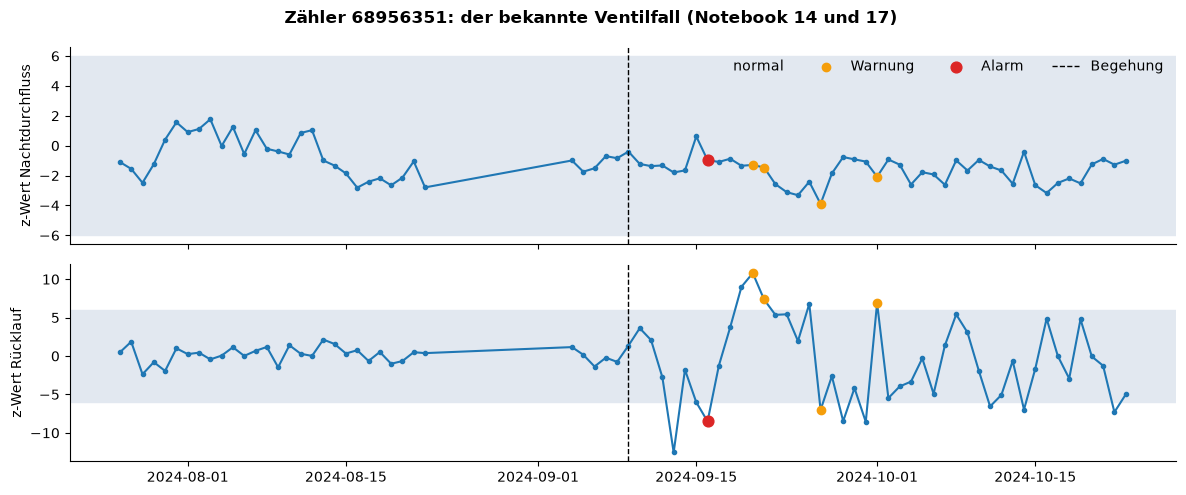

Begehung 09.09.2024, erster Alarm danach: 16.09.2024 (7 Tage)


In [14]:
FALL = 68956351
if FALL in begangen_tab.index:
    datum = begangen_tab.loc[FALL, "erste_begehung"]
    t = betrieb[(betrieb["zaehler"] == FALL) & (betrieb["tag"] >= datum - pd.Timedelta(days=45)) & (betrieb["tag"] < datum + pd.Timedelta(days=45))]
    fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
    for ax, spalte, titel in ((axes[0], "z_fluss", "z-Wert Nachtdurchfluss"), (axes[1], "z_rl", "z-Wert Rücklauf")):
        ax.plot(t["tag"], t[spalte], "o-", ms=3)
        ax.axhspan(-SCHWELLE, SCHWELLE, color="#E2E8F0", label="normal")
        ax.scatter(t.loc[t["warnung"], "tag"], t.loc[t["warnung"], spalte], color="#F59E0B", zorder=3, label="Warnung")
        ax.scatter(t.loc[t["alarm"], "tag"], t.loc[t["alarm"], spalte], color="#DC2626", s=60, zorder=4, label="Alarm")
        ax.axvline(datum, color="black", ls="--", lw=1, label="Begehung")
        ax.set_ylabel(titel)
        ax.spines[["top", "right"]].set_visible(False)
    axes[0].legend(frameon=False, ncol=4)
    fig.suptitle(f"Zähler {FALL}: der bekannte Ventilfall (Notebook 14 und 17)", fontweight="bold")
    fig.tight_layout()
    plt.show()
    erste = t[(t["tag"] >= datum) & t["alarm"]]["tag"].min()
    print(f"Begehung {datum:%d.%m.%Y}, erster Alarm danach: {erste:%d.%m.%Y} ({(erste - datum).days} Tage)")

- Zeigt für den bekannten Ventilfall 68956351 die beiden z-Werte rund um die Begehung. Grau ist der Normalbereich, gelb sind Warntage, rot ist der Alarm.
- Der Fall ist schon aus dem Kennlinienmonitor (Notebook 13) und dem Normalverhaltensmodell (Notebook 18) bekannt.

- Vor der Begehung am 09.09.2024 liegt alles im Normalbereich, obwohl das Ventil seit Jahren offen stand. Der Wächter vergleicht die Station mit sich selbst; das offene Ventil war ihr Normalzustand.
- Nach dem Tausch fällt der Rücklauf weit unter die Erwartung, am vierten Tag um 15 Streuungen. Die Station kühlt plötzlich viel besser aus, wie es ein neues Ventil bewirken soll.
- Der erste Alarm kommt nach 7 Tagen. Der Ausschlag am vierten Tag war ein einzelner Tag, die Warnregel verlangt zwei Tage hintereinander.
- Beim Nachtdurchfluss ändert sich weniger. Im September wird schon wieder geheizt, nachts fließt also ohnehin Wasser.

## 10 Haus oder Netz?

- Warnen viele Stationen am selben Tag, liegt es selten an jedem einzelnen Haus, eher am Netz (Vorlauftemperatur, Pumpen, Umstellung in der Heizzentrale).
- Der Wächter zählt deshalb, wie viele Stationen am selben Tag warnen.
- Zum Vergleich steht dabei dieselbe Zählung ohne Faktor je Jahreszeit.

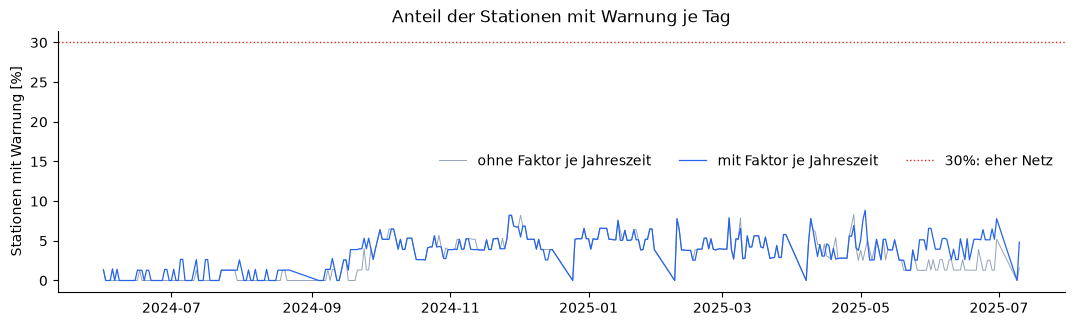

Median je Monat (Anteil der Stationen mit Warnung, %):
tag                       2024-06  2024-07  2024-08  2024-09  2024-10  2024-11  2024-12  2025-01  2025-02  2025-03  2025-04  2025-05  2025-06  2025-07
mit Faktor je Jahreszeit      0.0      1.3      0.0      2.7      4.2      4.0      5.2      5.2      3.9      4.2      3.9      3.8      5.1      2.4
ohne Faktor                   0.0      0.0      0.0      1.3      4.2      5.2      5.2      5.2      3.9      4.2      4.1      2.6      1.3      0.8


zaehler,begangene HAST,nie begangen
tag,,
2024Q2,0.4,0.5
2024Q3,1.1,1.9
2024Q4,2.1,9.0
2025Q1,2.7,8.4
2025Q2,2.9,6.6
2025Q3,0.0,6.5


In [15]:
ohne_faktor = z_werte(tag_abw[["zaehler", "tag", "heiztag", "res_rl", "res_fluss_nacht", "abschnitt"]], kal, None)
ohne_faktor["warnung"] = warnungen(ohne_faktor, SCHWELLE)
vergleich = pd.DataFrame({
    "mit Faktor je Jahreszeit": betrieb[betrieb["abschnitt"] != "Training"].groupby("tag")["warnung"].mean(),
    "ohne Faktor": ohne_faktor[ohne_faktor["zaehler"].isin(kal.index) & (ohne_faktor["abschnitt"] != "Training")].groupby("tag")["warnung"].mean(),
    "Stationen": betrieb[betrieb["abschnitt"] != "Training"].groupby("tag").size(),
})
vergleich = vergleich[(vergleich["Stationen"] >= 20) & (vergleich.index >= LERNEN_BIS)]
NETZ_ANTEIL = 0.3
fig, ax = plt.subplots(figsize=(13, 3.4))
ax.plot(vergleich.index, vergleich["ohne Faktor"] * 100, lw=0.7, color="#94A3B8", label="ohne Faktor je Jahreszeit")
ax.plot(vergleich.index, vergleich["mit Faktor je Jahreszeit"] * 100, lw=0.9, color="#2563EB", label="mit Faktor je Jahreszeit")
ax.axhline(NETZ_ANTEIL * 100, color="#DC2626", ls=":", lw=1, label=f"{NETZ_ANTEIL:.0%}: eher Netz")
ax.set_ylabel("Stationen mit Warnung [%]")
ax.set_title("Anteil der Stationen mit Warnung je Tag")
ax.legend(frameon=False, ncol=3)
ax.spines[["top", "right"]].set_visible(False)
plt.show()
monat = vergleich[["mit Faktor je Jahreszeit", "ohne Faktor"]].groupby(vergleich.index.to_period("M")).median()
print("Median je Monat (Anteil der Stationen mit Warnung, %):")
print((monat * 100).round(1).T.to_string())

#wer warnt? begangene gegen nie begangene Stationen
spaeter = betrieb[betrieb["tag"] >= LERNEN_BIS]
gruppe = spaeter["zaehler"].isin(labels.index).map({True: "begangene HAST", False: "nie begangen"})
(spaeter.groupby([spaeter["tag"].dt.to_period("Q"), gruppe])["warnung"].mean().unstack() * 100).round(1).dropna()

- Zählt je Kalendertag den Anteil der Stationen mit Warnung, mit und ohne Faktor je Jahreszeit. Nur Tage mit mindestens 20 vorhergesagten Stationen.
- Tage, an denen mindestens 30 % der Stationen gleichzeitig warnen, gelten als Netz-Tage. Eine Warnung an einem solchen Tag geht an den Netzbetreiber, nicht an den Hauseigentümer.
- Die letzte Tabelle zeigt je Quartal, an wie viel Prozent ihrer Tage begangene und nie begangene Stationen warnen.

- An keinem Tag warnen 30 % der Stationen gleichzeitig, der höchste Wert liegt bei 14 %. Ein Netzereignis, das viele Stationen zugleich trifft, gibt es in diesen Daten nicht.
- Der Faktor je Jahreszeit verschiebt wenig. Im Sommer gibt es mehr Warnungen (Juni/Juli 2024: 2,6 bis 2,8 % statt 0 bis 1,3 %, Juni 2025: 9,8 % statt 2,6 %), im Winter ändert sich fast nichts (Dezember 6,5 % mit und ohne).
- Im Winter 24/25 warnen begangene Stationen an 3 bis 6 % ihrer Tage, nie begangene an 10 bis 12 %. In der vorigen Fassung war es umgekehrt (7 bis 11 % gegen 1 bis 3 %).
  - Der Unterschied kommt fast nur von vier nie begangenen Stationen, die erst in dieser Fassung überwacht werden (72135480, 72167793, 80956410, 80912185). Drei davon warnen an mehr als zwei Dritteln ihrer Wintertage.
  - Ihre normale Schwankung stammt aus nur 14 Validierungstagen (bei 72135480 aus 44), alle aus dem Winter 23/24. Zwei von ihnen hatten im Sommer 2024 nachts 371 bzw. 801 l/h Durchfluss, also das Ventilbild.
  - Ohne diese vier bleibt das Bild der vorigen Fassung: übrige nie begangene unter 1 % ihrer Wintertage, begangene etwa 5 %. Die begangenen Stationen arbeiten nach dem Eingriff anders als in der Lernzeit, und der Wächter meldet das zu Recht.
- Für den Betrieb: Nach einem bekannten Eingriff muss der Wächter die Station neu kennenlernen (neue normale Schwankung, im besten Fall nachtrainiert), sonst meldet er dieselbe Veränderung immer wieder. Und eine Station sollte erst überwacht werden, wenn ihre normale Schwankung aus genug Tagen beider Jahreszeiten stammt; mindestens 10 Validierungstage reichen dafür nicht.

## 11 Ergebnis speichern

- Speichert die Tagesergebnisse aller überwachten Zähler nach `data/processed/prognose_tage.csv`.

In [16]:
aus = betrieb[["zaehler", "tag", "abschnitt", "heiztag", "res_rl", "res_fluss_nacht", "z_rl", "z_fluss", "warnung", "alarm"]].copy()
z_alle = z_werte(abw_alle, kal_alle, faktor_alle)       #dasselbe für das Netz auf allen HAST (Vergleich in NB 30)
aus["z_rl_alle"] = z_alle["z_rl"].reindex(aus.index)
aus["z_fluss_alle"] = z_alle["z_fluss"].reindex(aus.index)
aus.to_csv(PROCESSED / "prognose_tage.csv", index=False)
print(f"prognose_tage.csv: {len(aus):,} Zähler-Tage von {aus['zaehler'].nunique()} Zählern; Schwelle z ≥ {SCHWELLE}")
aus.head()

prognose_tage.csv: 58,524 Zähler-Tage von 87 Zählern; Schwelle z ≥ 6


,zaehler,tag,abschnitt,heiztag,res_rl,res_fluss_nacht,z_rl,z_fluss,warnung,alarm,z_rl_alle,z_fluss_alle
7,53198226,2022-11-20,Validierung,True,6.276537,-32.612806,1.799249,0.188486,False,False,3.051005,0.935258
8,53198226,2022-11-21,Training,True,-10.763925,-43.566828,-2.883157,0.029462,False,False,-1.931806,-0.077649
9,53198226,2022-11-22,Training,True,-0.887652,-49.990298,-0.169339,-0.063791,False,False,0.589223,0.615888
10,53198226,2022-11-23,Training,True,-2.558229,18.017238,-0.628382,0.923504,False,False,0.091818,1.507533
11,53198226,2022-11-24,Training,True,-4.051540,45.642729,-1.038717,1.324556,False,False,-0.565132,1.542029


- `prognose_tage.csv`: 58.524 Zähler-Tage von 87 Zählern mit Abweichung, z-Werten, Warnung und Alarm, Schwelle z ≥ 4.
- Notebook 29 fasst die Tage vor der Begehung je Station zusammen. Notebook 30 vergleicht die Alarme mit dem Normalverhaltensmodell.
- `z_rl_alle` und `z_fluss_alle` sind die z-Werte des Vergleichsnetzes auf allen HAST. Damit prüft Notebook 30, ob die Vorgabe den Vergleich verändert.

## Zusammenfassung & Bewertung

**Ergebnis**
- Ein Encoder-Decoder-LSTM (35.000 Gewichte, 24 Sekunden Training auf der GPU) sagt für 87 Stationen jeden Tag Rücklauf und Durchfluss vorher. Gelernt nach Vorgabe nur auf begangenen HAST, ein Netz auf allen HAST dient zum Vergleich.
- Warnregel: z ≥ 4 an zwei Tagen hintereinander, mit Faktor je Jahreszeit. Ein Alarm je Veränderung, gezählt wie beim Normalverhaltensmodell.
- Bei eingerechneten Fehlern erkannt (8 % Fehlalarme): Bypass 150 l/h zu 84 %, Bypass 50 l/h zu 55 %, hängender Fühler zu 43 %, Sollwert +5 K zu 19 %.
- Der Wächter sucht neue Fehler, das ganze Jahr und auf Stundenbasis. Fehler, die es schon immer gab, sieht er nicht (Beispiel Ventilfall 68956351); dafür sind Notebook 27 und 29 da.
- `prognose_tage.csv` geht an Notebook 29 und 30.

**Belastbar**
- Die Rücklauf-Vorhersage ist deutlich besser als einfache Regeln: 4,3 K gegen 6,2 K („wie gestern“), auch bei nie gesehenen Stationen besser als „wie gestern“.
- Ein plötzlich offenes Ventil (Bypass 150 l/h) findet der Wächter meist innerhalb von acht Tagen, bei 8 % Fehlalarmen im Sommer.
- Die Alarmmenge ist handhabbar: 2,9 je Station und Jahr (Normalverhaltensmodell: 3,6), in derselben Einheit gemessen.

**Schwach**
- Hängender Fühler (43 %) und Sollwert +5 K (19 %) werden schlecht erkannt. 5 K liegen in der normalen Schwankung von Tag zu Tag; dafür sind Vergleiche über Wochen besser geeignet, etwa die Kennlinie mit CUSUM in Notebook 18.
- Bei nie begangenen Stationen ist die Durchfluss-Vorhersage schlechter als „wie gestern“ (208 gegen 142 l/h). Das ist der Preis der Vorgabe.
- Alarme nach echten Begehungen: 11 bis 17 % gegen 13 % bei nie begangenen Stationen, auch mit der Prüfung aus Notebook 18 kein Vorsprung (Notebook 30). Eine Begehung verschiebt den Betrieb nur um etwa eine halbe Streuung; der CUSUM des Normalverhaltensmodells bemerkt das bei gleich vielen Alarmen in 30 von 43 Fällen, dieses LSTM in 16.
- Die Winterwarnungen kommen von Stationen, die sich nach der Begehung verändert haben, und von vier nie begangenen Stationen mit zu wenigen Lerntagen. Haus oder Netz ließ sich nicht prüfen, weil es in den Daten keinen Netz-Tag gibt.

**Offen**
- Für den Betrieb braucht es ein Neukalibrieren nach jedem bekannten Eingriff und genug Lerntage aus beiden Jahreszeiten, bevor eine Station überwacht wird. Wie viele Tage reichen, ist offen.